## 🚚 Analyse de la Logistique et Optimisation de Tournées


### 📝 Description du Sujet


Ce projet vise à résoudre un problème classique de recherche opérationnelle : le Vehicle Routing Problem (VRP) ou problème de tournées de véhicules. Il s'agit de déterminer les itinéraires optimaux pour une flotte de véhicules devant desservir un ensemble de clients géographiquement dispersés, tout en minimisant les coûts (distance, temps, carburant) et en respectant des contraintes opérationnelles (capacité des camions, fenêtres de livraison).

Le projet couvre l'ensemble du pipeline de la donnée : de l'exploration géospatiale (EDA) à la résolution mathématique (OR-Tools), jusqu'à la visualisation interactive via une application web (Streamlit).

### 🎯 Objectifs


Explorer et nettoyer les données logistiques (adresses, poids des colis, contraintes horaires).

Visualiser les points de livraison sur une carte interactive (GeoPandas / PyDeck).

Modéliser le problème sous forme de graphe (matrice de distances/temps).

Implémenter un solveur d'optimisation avec Google OR-Tools pour générer des tournées efficaces.

Déployer une interface utilisateur interactive avec Streamlit permettant de charger un fichier de commandes et de visualiser les itinéraires optimisés.

### 🗺️ Plan du Projet


Introduction & Contexte

Enjeux de la logistique du dernier kilomètre.

Présentation des outils (Python, OR-Tools, Streamlit).

Analyse Exploratoire des Données (EDA)

Chargement et nettoyage des données.

Géocodage des adresses (conversion en Latitude/Longitude).

Analyse des volumes et des zones géographiques.

Modélisation du Problème

Construction de la matrice de distances (Haversine ou API OSRM).

Définition des contraintes (capacité, nombre de véhicules).

Résolution avec OR-Tools

Implémentation du solveur VRP.

Extraction et interprétation des solutions.

Interface Interactive (Streamlit)

Développement de l'application web.

Visualisation cartographique dynamique (PyDeck).

Conclusion & Perspectives

Limites du modèle actuel.

Améliorations futures (fenêtres de temps, trafic en temps réel).

### 📑 Table des Matières


Description du Sujet

Objectifs

Plan du Projet

Table des Matières

Structure du Projet

Prérequis et Installation

Étape 1 : Analyse Exploratoire (EDA)

Étape 2 : Optimisation avec OR-Tools

Étape 3 : Interface Streamlit

### 📂 Structure du Projet


In [ ]:
Projet_Logistique/
│
├── data/
│   ├── commandes.csv          # Données brutes (clients, adresses, poids)
│   └── matrice_distances.csv  # Matrice générée pour OR-Tools
│
├── notebooks/
│   └── EDA.ipynb              # Exploration, nettoyage et tests
│
├── src/
│   ├── optimizer.py           # Logique OR-Tools (VRP solver)
│   └── utils.py               # Fonctions de géocodage et calculs
│
├── app.py                     # Application Streamlit
├── requirements.txt           # Dépendances du projet
└── README.md                  # Documentation du projet

### ⚙️ Prérequis et Installation


In [11]:
conda create -n logistique python=3.10 -y

Retrieving notices: ...working... done
Channels:
 - defaults
Platform: win-64
Solving environment: ...working... done

## Package Plan ##

  environment location: C:\Users\ADMIN\anaconda3\envs\logistique

  added / updated specs:
    - python=3.10


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    bzip2-1.0.8                |       h2bbff1b_6          90 KB
    libexpat-2.9.0             |       hd7fb8db_0         130 KB
    libffi-3.4.8               |       h42d73b9_3         118 KB
    libzlib-1.3.2              |       h1c6eee0_0          63 KB
    packaging-26.3             |  py310haa95532_0         326 KB
    pip-26.2.1                 |     pyhc872135_0         1.1 MB
    python-3.10.22             |       hb00fc5c_0        14.8 MB
    setuptools-84.0.0          |  py310haa95532_0         968 KB
    sqlite-3.53.4              |       hee5a0db_0         946 KB
    vc-14.3          

Error while loading conda entry point: conda-anaconda-telemetry (cannot import name 'CondaRequestHeader' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: conda-anaconda-tos (cannot import name 'CondaPreCommand' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: repo (cannot import name 'CondaSubcommand' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: conda-anaconda-telemetry (cannot import name 'CondaRequestHeader' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: conda-anaconda-tos (cannot import name 'CondaPreCommand' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: repo (cannot

In [12]:
conda activate logistique


Note: you may need to restart the kernel to use updated packages.


Error while loading conda entry point: conda-anaconda-telemetry (cannot import name 'CondaRequestHeader' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: conda-anaconda-tos (cannot import name 'CondaPreCommand' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: repo (cannot import name 'CondaSubcommand' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: conda-anaconda-telemetry (cannot import name 'CondaRequestHeader' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: conda-anaconda-tos (cannot import name 'CondaPreCommand' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: repo (cannot

In [13]:
pip install ortools pandas geopandas streamlit pydeck folium

Note: you may need to restart the kernel to use updated packages.


In [15]:
conda create -n logistique python=3.10 -y

Channels:
 - defaults
Platform: win-64
Solving environment: ...working... done

## Package Plan ##

  environment location: C:\Users\ADMIN\anaconda3\envs\logistique

  added / updated specs:
    - python=3.10


The following NEW packages will be INSTALLED:

  bzip2              pkgs/main/win-64::bzip2-1.0.8-h2bbff1b_6 
  ca-certificates    pkgs/main/win-64::ca-certificates-2026.9.25-haa95532_0 
  libexpat           pkgs/main/win-64::libexpat-2.9.0-hd7fb8db_0 
  libffi             pkgs/main/win-64::libffi-3.4.8-h42d73b9_3 
  libzlib            pkgs/main/win-64::libzlib-1.3.2-h1c6eee0_0 
  openssl            pkgs/main/win-64::openssl-3.5.9-hbb43b14_0 
  packaging          pkgs/main/win-64::packaging-26.3-py310haa95532_0 
  pip                pkgs/main/noarch::pip-26.2.1-pyhc872135_0 
  python             pkgs/main/win-64::python-3.10.22-hb00fc5c_0 
  setuptools         pkgs/main/win-64::setuptools-84.0.0-py310haa95532_0 
  sqlite             pkgs/main/win-64::sqlite-3.53.4-hee5a0db_0 
  

Error while loading conda entry point: conda-anaconda-telemetry (cannot import name 'CondaRequestHeader' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: conda-anaconda-tos (cannot import name 'CondaPreCommand' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: repo (cannot import name 'CondaSubcommand' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: conda-anaconda-telemetry (cannot import name 'CondaRequestHeader' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: conda-anaconda-tos (cannot import name 'CondaPreCommand' from 'conda.plugins' (C:\Users\ADMIN\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: repo (cannot

In [16]:
pip install ortools pandas geopandas streamlit pydeck folium jupyter


   ----------- ---------------------------- 2/7 [lark]
   ----------- ---------------------------- 2/7 [lark]
   ----------- ---------------------------- 2/7 [lark]
   ---------------------------- ----------- 5/7 [rfc3987-syntax]
   ---------------------------------------- 7/7 [isoduration]

Note: you may need to restart the kernel to use updated packages.


## 🔍 Étape 1 : Analyse Exploratoire (EDA) vec GeoPandas


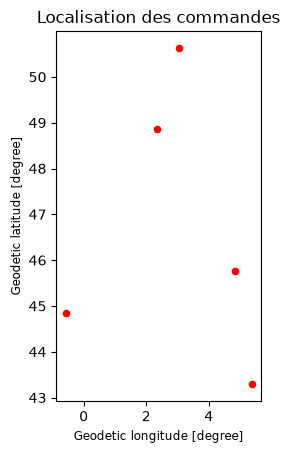

In [8]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt

# 1. Charger les données (exemple fictif)
# Remplaçez par pd.read_csv('data/commandes.csv')
data = {
    'id_client': [1, 2, 3, 4, 5],
    'adresse': ['Paris', 'Lyon', 'Marseille', 'Bordeaux', 'Lille'],
    'poids_kg': [10, 5, 20, 15, 8]
}
df = pd.DataFrame(data)

# 2. Géocodage (Simulation ici, mais utilisez geopy ou l'API Google Maps/OSM en vrai)
# Exemple de coordonnées (Lat, Lon)
coords = {
    'Paris': (48.8566, 2.3522),
    'Lyon': (45.7640, 4.8357),
    'Marseille': (43.2965, 5.3698),
    'Bordeaux': (44.8378, -0.5792),
    'Lille': (50.6292, 3.0573)
}
df['lat'] = df['adresse'].map(lambda x: coords[x][0])
df['lon'] = df['adresse'].map(lambda x: coords[x][1])

# 3. Créer un GeoDataFrame
geometry = [Point(xy) for xy in zip(df['lon'], df['lat'])]
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")

# 4. Visualisation rapide
# (Sur Streamlit, vous utiliserez st.map ou pydeck plus tard)
gdf.plot(marker='o', color='red', markersize=20)
plt.title("Localisation des commandes")
plt.show()

### Étape 2 : L'Optimisation avec OR-Tools


In [1]:
from ortools.constraint_solver import routing_enums_pb2
from ortools.constraint_solver import pywrapcp
import math

def haversine(lat1, lon1, lat2, lon2):
    # Calcul de la distance en km entre deux points
    R = 6371.0
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    a = math.sin(dlat / 2)**2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    return R * c

def create_distance_matrix(locations):
    # locations: liste de tuples (lat, lon)
    matrix = []
    for from_loc in locations:
        row = []
        for to_loc in locations:
            row.append(int(haversine(from_loc[0], from_loc[1], to_loc[0], to_loc[1]) * 1000)) # en mètres
        matrix.append(row)
    return matrix

def solve_vrp(distance_matrix, num_vehicles=1, depot=0):
    # Création du gestionnaire de routage
    manager = pywrapcp.RoutingIndexManager(len(distance_matrix), num_vehicles, depot)
    routing = pywrapcp.RoutingModel(manager)

    # Callback pour la distance
    def distance_callback(from_index, to_index):
        from_node = manager.IndexToNode(from_index)
        to_node = manager.IndexToNode(to_index)
        return distance_matrix[from_node][to_node]

    transit_callback_index = routing.RegisterTransitCallback(distance_callback)
    routing.SetArcCostEvaluatorOfAllVehicles(transit_callback_index)

    # Paramètres de recherche
    search_parameters = pywrapcp.DefaultRoutingSearchParameters()
    search_parameters.first_solution_strategy = (
        routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC)

    # Résolution
    solution = routing.SolveWithParameters(search_parameters)
    
    # Extraction de l'itinéraire (à adapter selon vos besoins)
    if solution:
        index = routing.Start(0)
        route = []
        while not routing.IsEnd(index):
            route.append(manager.IndexToNode(index))
            index = solution.Value(routing.NextVar(index))
        return route
    return None

In [2]:
import ortools
from ortools.constraint_solver import routing_enums_pb2
from ortools.constraint_solver import pywrapcp

print(f"Version d'OR-Tools : {ortools.__version__}")
print("Importation réussie !")

Version d'OR-Tools : 9.15.6755
Importation réussie !


### Importation des bibliothèques

In [3]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt
import math

# 1. Création d'un jeu de données de test (Commandes)
data = {
    'ID_Commande': ['CMD01', 'CMD02', 'CMD03', 'CMD04', 'CMD05', 'CMD06'],
    'Ville': ['Paris', 'Lyon', 'Marseille', 'Bordeaux', 'Lille', 'Toulouse'],
    'Poids_Kg': [10, 5, 20, 15, 8, 12],
    'Lat': [48.8566, 45.7640, 43.2965, 44.8378, 50.6292, 43.6047],
    'Lon': [2.3522, 4.8357, 5.3698, -0.5792, 3.0573, 1.4442]
}

df = pd.DataFrame(data)
display(df)

,ID_Commande,Ville,Poids_Kg,Lat,Lon
0,CMD01,Paris,10,48.8566,2.3522
1,CMD02,Lyon,5,45.7640,4.8357
2,CMD03,Marseille,20,43.2965,5.3698
3,CMD04,Bordeaux,15,44.8378,-0.5792
4,CMD05,Lille,8,50.6292,3.0573
5,CMD06,Toulouse,12,43.6047,1.4442


In [12]:
import pandas as pd
import numpy as np

# Paramètres
n_clients = 50
np.random.seed(42) # Pour avoir toujours les mêmes données à chaque génération

# 1. Le Dépôt (Paris)
depot = pd.DataFrame({
    'ID': ['DEPOT'], 
    'Latitude': [48.8566], 
    'Longitude': [2.3522], 
    'Poids_Kg': [0]
})

# 2. Génération des clients (rayon d'environ 400km autour de Paris)
# On utilise une distribution normale pour simuler un cluster urbain
lats = np.random.normal(48.8566, 2.0, n_clients) 
lons = np.random.normal(2.3522, 2.0, n_clients)
poids = np.random.randint(1, 25, n_clients) # Poids entre 1 et 25 kg

clients = pd.DataFrame({
    'ID': [f'CLI_{i:03d}' for i in range(1, n_clients + 1)],
    'Latitude': lats,
    'Longitude': lons,
    'Poids_Kg': poids
})

# 3. Fusion et sauvegarde
df_final = pd.concat([depot, clients], ignore_index=True)
df_final.to_csv('commandes.csv', index=False)

print(f"Fichier 'commandes.csv' généré avec {n_clients} clients !")
print(f"Poids total à livrer : {df_final['Poids_Kg'].sum()} kg")
display(df_final.head())

Fichier 'commandes.csv' généré avec 50 clients !
Poids total à livrer : 648 kg


,ID,Latitude,Longitude,Poids_Kg
0,DEPOT,48.856600,2.352200,0
1,CLI_001,49.850028,3.000368,9
2,CLI_002,48.580071,1.582035,5
3,CLI_003,50.151977,0.998356,1
4,CLI_004,51.902660,3.575553,19


###  Visualisation avec GeoPandas

 la carte pour voir où se trouvent nos clients.

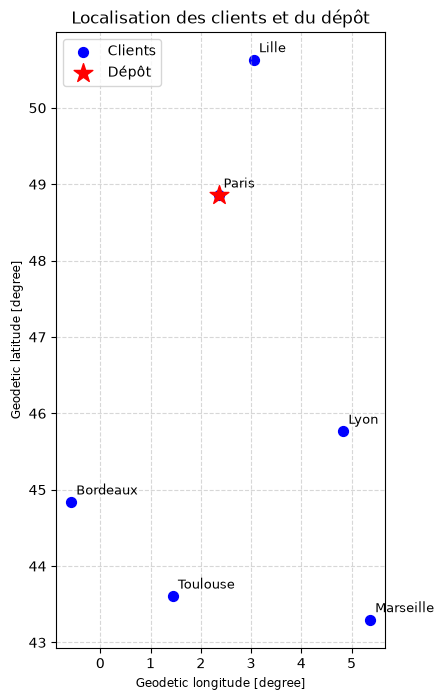

In [4]:
# 1. Transformation en GeoDataFrame
geometry = [Point(xy) for xy in zip(df['Lon'], df['Lat'])]
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")

# 2. Ajout d'un point de départ (Le Dépôt) - On va prendre Paris comme dépôt
# On l'ajoute visuellement en rouge
depot = gpd.GeoDataFrame(
    {'Nom': ['Dépôt']}, 
    geometry=[Point(2.3522, 48.8566)], # Coordonnées de Paris
    crs="EPSG:4326"
)

# 3. Affichage
fig, ax = plt.subplots(figsize=(10, 8))
gdf.plot(ax=ax, color='blue', marker='o', markersize=50, label='Clients')
depot.plot(ax=ax, color='red', marker='*', markersize=200, label='Dépôt')

# Ajout des noms des villes
for x, y, label in zip(gdf.geometry.x, gdf.geometry.y, gdf['Ville']):
    ax.text(x + 0.1, y + 0.1, label, fontsize=9)

plt.title("Localisation des clients et du dépôt")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

###  Le calcul des distances (Matrice)

OR-Tools a besoin de savoir à quelle distance chaque point est de tous les autres. Pour simplifier ici, on utilise la distance à vol d'oiseau (Haversine).



In [5]:
def haversine(lat1, lon1, lat2, lon2):
    """Calcule la distance en kilomètres entre deux points GPS."""
    R = 6371.0 # Rayon de la Terre en km
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    a = math.sin(dlat / 2)**2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    return R * c

# Création de la liste des coordonnées : [Dépôt, CMD01, CMD02, ...]
# Le dépôt est à l'index 0, les clients suivent.
locations = [(48.8566, 2.3522)] + list(zip(df['Lat'], df['Lon']))

# Calcul de la matrice de distances
n = len(locations)
distance_matrix = [[0] * n for _ in range(n)]

for i in range(n):
    for j in range(n):
        distance_matrix[i][j] = int(haversine(locations[i][0], locations[i][1], locations[j][0], locations[j][1]) * 1000) # En mètres pour OR-Tools

print("Matrice de distances (en mètres) générée avec succès !")
print(f"Dimensions : {n}x{n}")

Matrice de distances (en mètres) générée avec succès !
Dimensions : 7x7


### Résolution avec OR-Tools

On va demander à OR-Tools de trouver le chemin le plus court pour un camion (qui part du dépôt et y revient).

In [6]:
from ortools.constraint_solver import routing_enums_pb2
from ortools.constraint_solver import pywrapcp

def solve_vrp(distance_matrix, num_vehicles=1, depot_index=0):
    # 1. Création du gestionnaire de routage
    manager = pywrapcp.RoutingIndexManager(len(distance_matrix), num_vehicles, depot_index)
    routing = pywrapcp.RoutingModel(manager)

    # 2. Callback pour la distance
    def distance_callback(from_index, to_index):
        from_node = manager.IndexToNode(from_index)
        to_node = manager.IndexToNode(to_index)
        return distance_matrix[from_node][to_node]

    transit_callback_index = routing.RegisterTransitCallback(distance_callback)
    routing.SetArcCostEvaluatorOfAllVehicles(transit_callback_index)

    # 3. Paramètres de recherche
    search_parameters = pywrapcp.DefaultRoutingSearchParameters()
    search_parameters.first_solution_strategy = (
        routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC)

    # 4. Résolution
    solution = routing.SolveWithParameters(search_parameters)

    # 5. Extraction de l'itinéraire
    if solution:
        index = routing.Start(0)
        route = []
        route_distance = 0
        while not routing.IsEnd(index):
            node = manager.IndexToNode(index)
            route.append(node)
            previous_index = index
            index = solution.Value(routing.NextVar(index))
            route_distance += routing.GetArcCostForVehicle(previous_index, index, 0)
        
        # Ajouter le retour au dépôt
        route.append(manager.IndexToNode(index))
        
        return route, route_distance
    else:
        return None, None

# Lancement de l'optimisation
route, distance = solve_vrp(distance_matrix)

if route:
    print(f"Tournée optimale trouvée !")
    print(f"Distance totale : {distance / 1000:.2f} km")
    
    # Affichage du chemin
    villes = ['Dépôt'] + df['Ville'].tolist()
    itineraire_noms = [villes[i] for i in route]
    print("Itinéraire : " + " -> ".join(itineraire_noms))

Tournée optimale trouvée !
Distance totale : 2067.54 km
Itinéraire : Dépôt -> Paris -> Lille -> Lyon -> Marseille -> Toulouse -> Bordeaux -> Dépôt


### Visualiser l'itinéraire sur la carte


Maintenant, passons à la visualisation du trajet sur la carte. C'est bien beau d'avoir une liste de villes, mais un bon Data Scientist doit savoir présenter ses résultats visuellement.



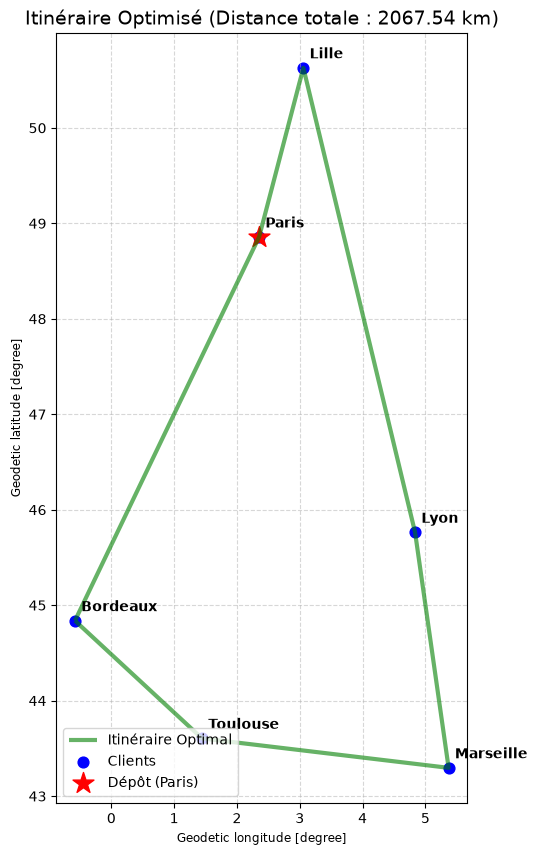

In [8]:
import matplotlib.pyplot as plt
from shapely.geometry import LineString

# 1. On récupère les coordonnées dans l'ordre de l'itinéraire
# On utilise la liste 'locations' qu'on avait créée (qui contient le dépôt en index 0)
coords_itineraire = [locations[i] for i in route]

# 2. On crée une "Ligne" (LineString) pour le tracé
# Attention : Shapely attend (Longitude, Latitude) et non (Latitude, Longitude)
ligne_geometrie = LineString([(lon, lat) for lat, lon in coords_itineraire])
gdf_ligne = gpd.GeoDataFrame({'Nom': ['Itinéraire']}, geometry=[ligne_geometrie], crs="EPSG:4326")

# 3. Affichage
fig, ax = plt.subplots(figsize=(10, 10))

# On dessine la ligne de l'itinéraire en vert
gdf_ligne.plot(ax=ax, color='green', linewidth=3, alpha=0.6, label='Itinéraire Optimal')

# On redessine les points par-dessus
gdf.plot(ax=ax, color='blue', marker='o', markersize=60, label='Clients')
depot.plot(ax=ax, color='red', marker='*', markersize=250, label='Dépôt (Paris)')

# Ajout des étiquettes (Noms des villes)
for x, y, label in zip(gdf.geometry.x, gdf.geometry.y, gdf['Ville']):
    ax.text(x + 0.1, y + 0.1, label, fontsize=10, fontweight='bold')

plt.title(f"Itinéraire Optimisé (Distance totale : {distance/1000:.2f} km)", fontsize=14)
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Ajouter une contrainte de capacité (Le vrai défi logistique)

Actuellement, notre camion peut tout porter. Mais dans la vraie vie, un camion a un poids maximum. Imaginons que notre camion ne puisse porter que 35 kg maximum.

Regardons nos données :

Lille (8) + Paris (10) + Lyon (5) + Marseille (20) + Toulouse (12) + Bordeaux (15) = 70 kg.
Un seul camion ne suffira pas ! Il va falloir en envoyer deux.

In [9]:
def solve_vrp_capacite(distance_matrix, demandes, capacite_max_vehicule, num_vehicles=2, depot_index=0):
    # 1. Initialisation
    manager = pywrapcp.RoutingIndexManager(len(distance_matrix), num_vehicles, depot_index)
    routing = pywrapcp.RoutingModel(manager)

    # 2. Callback Distance (comme avant)
    def distance_callback(from_index, to_index):
        from_node = manager.IndexToNode(from_index)
        to_node = manager.IndexToNode(to_index)
        return distance_matrix[from_node][to_node]
    transit_callback_index = routing.RegisterTransitCallback(distance_callback)
    routing.SetArcCostEvaluatorOfAllVehicles(transit_callback_index)

    # 3. Callback Demande (Poids)
    def demand_callback(from_index):
        from_node = manager.IndexToNode(from_index)
        return demandes[from_node]
    demand_callback_index = routing.RegisterUnaryTransitCallback(demand_callback)

    # 4. AJOUT DE LA CONTRAINTE DE CAPACITÉ
    routing.AddDimensionWithVehicleCapacity(
        demand_callback_index,
        0,  # null capacity slack
        [capacite_max_vehicule] * num_vehicles,  # capacité max pour chaque véhicule
        True,  # start cumul to zero
        'Capacity'
    )

    # 5. Paramètres de recherche
    search_parameters = pywrapcp.DefaultRoutingSearchParameters()
    search_parameters.first_solution_strategy = (
        routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC)

    # 6. Résolution
    solution = routing.SolveWithParameters(search_parameters)

    # 7. Extraction des itinéraires pour CHAQUE véhicule
    if solution:
        routes = []
        total_distance = 0
        for vehicle_id in range(num_vehicles):
            index = routing.Start(vehicle_id)
            route = []
            route_distance = 0
            while not routing.IsEnd(index):
                node = manager.IndexToNode(index)
                route.append(node)
                previous_index = index
                index = solution.Value(routing.NextVar(index))
                route_distance += routing.GetArcCostForVehicle(previous_index, index, 0)
            route.append(manager.IndexToNode(index))
            routes.append(route)
            total_distance += route_distance
        return routes, total_distance
    else:
        return None, None

# --- Préparation des données ---
# Liste des poids : 0 pour le dépôt, puis les poids des commandes
demandes = [0] + df['Poids_Kg'].tolist() 
capacite = 40 # Un camion peut porter 40 kg max
nb_camions = 2 # On a 2 camions disponibles

# --- Lancement ---
routes, dist_totale = solve_vrp_capacite(distance_matrix, demandes, capacite, nb_camions)

# --- Affichage ---
if routes:
    villes = ['Dépôt'] + df['Ville'].tolist()
    print(f"Distance totale pour {nb_camions} camions : {dist_totale / 1000:.2f} km\n")
    
    for i, r in enumerate(routes):
        noms = [villes[node] for node in r]
        # Calcul du poids transporté pour ce camion
        poids_transporte = sum([demandes[node] for node in r])
        print(f"Camion {i+1} (Poids: {poids_transporte} kg) :")
        print(" -> ".join(noms))
        print("-" * 50)

Distance totale pour 2 camions : 2977.59 km

Camion 1 (Poids: 37 kg) :
Dépôt -> Toulouse -> Marseille -> Lyon -> Dépôt
--------------------------------------------------
Camion 2 (Poids: 33 kg) :
Dépôt -> Paris -> Bordeaux -> Lille -> Dépôt
--------------------------------------------------


#### Visualiser les deux tournées sur la carte

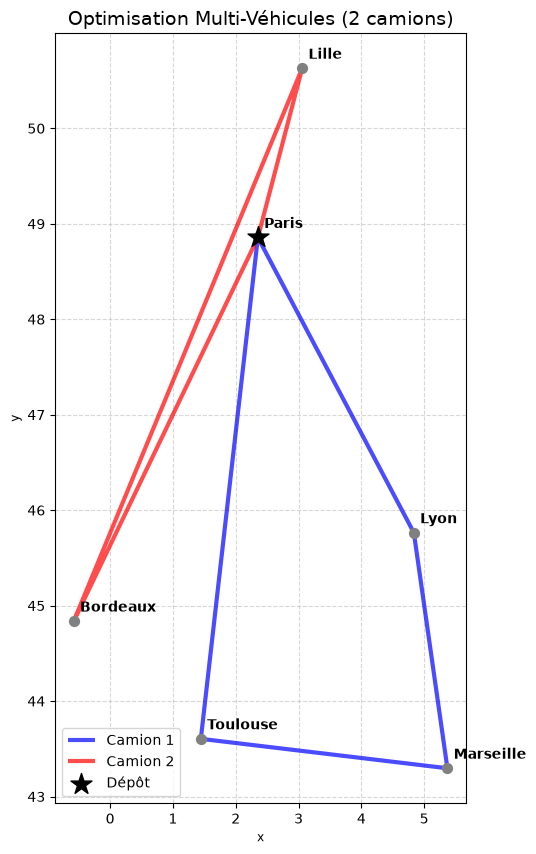

In [10]:
import matplotlib.pyplot as plt
from shapely.geometry import LineString

fig, ax = plt.subplots(figsize=(10, 10))

# Couleurs pour différencier les camions
couleurs_camions = ['blue', 'red', 'purple', 'orange']

# 1. Dessiner les lignes pour chaque camion
for i, r in enumerate(routes):
    # Récupération des coordonnées dans l'ordre
    coords = [locations[node] for node in r]
    # Inversion en (Lon, Lat) pour Shapely
    ligne_geom = LineString([(lon, lat) for lat, lon in coords])
    
    # On plot la ligne
    gpd.GeoSeries([ligne_geom]).plot(
        ax=ax, 
        color=couleurs_camions[i], 
        linewidth=3, 
        alpha=0.7, 
        label=f'Camion {i+1}'
    )

# 2. Redessiner les points et le dépôt par-dessus
gdf.plot(ax=ax, color='gray', marker='o', markersize=50, zorder=5)
depot.plot(ax=ax, color='black', marker='*', markersize=250, zorder=5, label='Dépôt')

# 3. Ajouter les noms des villes
for x, y, label in zip(gdf.geometry.x, gdf.geometry.y, gdf['Ville']):
    ax.text(x + 0.1, y + 0.1, label, fontsize=10, fontweight='bold', zorder=6)

plt.title(f"Optimisation Multi-Véhicules ({len(routes)} camions)", fontsize=14)
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()